In [49]:
# Preprocessing + PCA
import os
import cv2
import numpy as np
from glob import glob
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# CAE
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as T
from torchvision.utils import make_grid, save_image

# Preprocess images

### X_face

In [50]:
# Image preprocessing function
def preprocess_image(path, target_size=(64,64), gray=True, clahe=True):
    img = cv2.imread(path)                     # BGR
    if img is None:
        raise RuntimeError(f"failed to read {path}")
    # --- face alignment / crop step ---
    # Basic fallback: center-crop to preserve face region assuming face roughly centered.
    h, w = img.shape[:2]
    # crop central square region (or choose a fixed bbox based on FEI consistent capture)
    side = min(h, w)
    cx, cy = w//2, h//2
    x0, y0 = cx - side//2, cy - side//2
    crop = img[y0:y0+side, x0:x0+side]
    # --- convert to grayscale if requested ---
    if gray:
        crop = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    else:
        crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    # --- resize to target size ---
    img_resized = cv2.resize(crop, target_size, interpolation=cv2.INTER_AREA)
    # --- photometric normalization ---
    if gray and clahe:
        clahe_obj = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        img_resized = clahe_obj.apply(img_resized)
    elif gray:
        img_resized = cv2.equalizeHist(img_resized)
    else:
        # per-channel CLAHE
        if clahe:
            img_resized = cv2.cvtColor(img_resized, cv2.COLOR_RGB2LAB)
            l, a, b = cv2.split(img_resized)
            clahe_obj = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
            l = clahe_obj.apply(l)
            img_resized = cv2.merge((l,a,b))
            img_resized = cv2.cvtColor(img_resized, cv2.COLOR_LAB2RGB)
    return img_resized

- /Users/grantsfolder/Desktop/COGS_118B/Final_project/archive
/originalimages_part1/xx-xx.jpg

In [51]:
face_dirs = ["/Users/grantsfolder/Desktop/COGS_118B/Final_project/archive/originalimages_part1", 
              "/Users/grantsfolder/Desktop/COGS_118B/Final_project/archive/originalimages_part2", 
              "/Users/grantsfolder/Desktop/COGS_118B/Final_project/archive/originalimages_part3", 
              "/Users/grantsfolder/Desktop/COGS_118B/Final_project/archive/originalimages_part4"]

target_size = (128,128)     # recommended: (64,64) or (128,128)
grayscale = True
use_clahe = True
svd_solver = 'randomized'    # fast for large data

# Load and preprocess all face images
# Gather all .jpg files from the 4 archive parts, then select only those with y == 13 (filename x_y.jpg)
face_paths = []
for d in face_dirs:
    if os.path.isdir(d):
        face_paths.extend(sorted(glob(os.path.join(d, '*.jpg'))))
    else:
        print(f"Warning: directory not found: {d}")
# Filter filenames that end with _13 (before extension)
face_paths_selected = []
for p in face_paths:
    # 13: Front face
    if p[-6:-4] == '13':
        face_paths_selected.append(p)
print(f"Found {len(face_paths_selected)} images with y==13 (candidate forward faces).")
face_processed = []
face_labels = []
failed = []
for p in face_paths_selected:
    try:
        img = preprocess_image(p, target_size=target_size, gray=grayscale, clahe=use_clahe)
        face_processed.append(img.ravel().astype(np.float32))   # flatten
        # extract person id x from filename x_y.jpg
        face_labels.append(os.path.basename(p).split('_')[0])
    except Exception as e:
        failed.append((p, str(e)))

if len(face_processed) == 0:
    raise RuntimeError("No images were successfully preprocessed. Check paths and filename patterns.")

X_face = np.vstack(face_processed)   # shape (n_images, n_pixels)
print("Data matrix shape:", X_face.shape)
print("Labels count:", len(face_labels))
if failed:
    print("Failed to preprocess {0} files (first 5):".format(len(failed)), failed[:5])

# Save preprocessed data for later PCA training
np.save(f"X_face_{X_face.shape[0]}.npy", X_face)
# np.save("preprocessed_paths.npy", np.array(face_paths_selected))
# np.save("preprocessed_labels.npy", np.array(face_labels))

Found 200 images with y==13 (candidate forward faces).
Data matrix shape: (200, 16384)
Labels count: 200


### X_tex

In [52]:
# preprocess texture images
texture_dir = "/Users/grantsfolder/Desktop/COGS_118B/Final_project/texture"

# Load and preprocess all texture images
texture_paths = sorted(glob(os.path.join(texture_dir, '*.jpg')))
texture_processed = []
texture_labels = []
failed_texture = []
for p in texture_paths:
    try:
        img = preprocess_image(p, target_size=target_size, gray=grayscale, clahe=use_clahe)
        texture_processed.append(img.ravel().astype(np.float32))   # flatten
        # extract person id x from filename x_y.jpg
        texture_labels.append(os.path.basename(p).split('_')[0])
    except Exception as e:
        failed_texture.append((p, str(e)))
if len(texture_processed) == 0:
    raise RuntimeError("No texture images were successfully preprocessed. Check paths and filename patterns.")

X_tex = np.vstack(texture_processed)
print("Texture data matrix shape:", X_tex.shape)
if failed_texture:
    print("Failed preprocessing texture files (first 5):", failed_texture[:5])

Texture data matrix shape: (14, 16384)


### X_obj

In [76]:
# preprocess object images
object_dir = "/Users/grantsfolder/Desktop/COGS_118B/Final_project/object"

# Load and preprocess all object images
object_paths = sorted(glob(os.path.join(object_dir, '*.jpg')))
object_processed = []
object_labels = []
failed_object = []
for p in object_paths:
    try:
        img = preprocess_image(p, target_size=target_size, gray=grayscale, clahe=use_clahe)
        object_processed.append(img.ravel().astype(np.float32))   # flatten
        # extract person id x from filename x_y.jpg
        object_labels.append(os.path.basename(p).split('_')[0])
    except Exception as e:
        failed_object.append((p, str(e)))
if len(object_processed) == 0:
    raise RuntimeError("No object images were successfully preprocessed. Check paths and filename patterns.")
X_obj = np.vstack(object_processed)
print("Object data matrix shape:", X_obj.shape)
if failed_object:
    print("Failed preprocessing object files (first 5):", failed_object[:5])

Object data matrix shape: (5, 16384)


# PCA Training

In [66]:
# import X_face data
X_face = np.load("X_face_200.npy")

# PCA training
n_components = min(500, X_face.shape[0], X_face.shape[1])  # number of principal components

# Mean centering
mean_face = np.mean(X_face, axis=0)
X_centered = X_face - mean_face
# PCA: keep top n_components
pca = PCA(n_components=n_components, svd_solver=svd_solver, whiten=False, random_state=42)
pca.fit(X_centered)
components = pca.components_
explained = pca.explained_variance_ratio_
print("Explained variance of first 10 components:", explained[:10].sum())

Explained variance of first 10 components: 0.627309


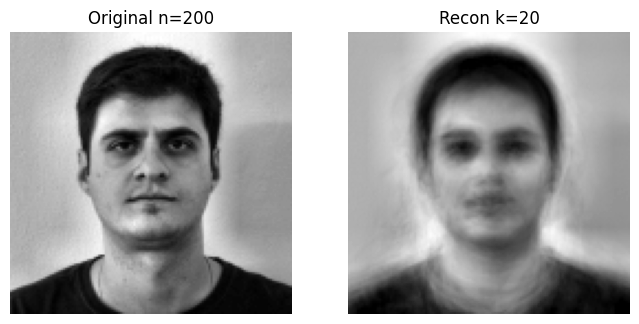

In [68]:
# Use k components to reconstruct face image
k = min(20, pca.n_components_)
img_idx = 0

# get PCA coefficients for the image
coeffs = pca.transform(X_centered[img_idx:img_idx+1])  # shape (1, n_components)

# manual reconstruction using only first k components
recon = mean_face + np.dot(coeffs[:, :k], components[:k, :])  # shape (1, n_pixels)
recon = recon.ravel()

# restore to image shape
if grayscale:
    recon_img = recon.reshape(target_size[::-1])
    orig_img = X_face[img_idx].reshape(target_size[::-1])
else:
    recon_img = recon.reshape((target_size[1], target_size[0], 3))
    orig_img = X_face[img_idx].reshape((target_size[1], target_size[0], 3))

recon_img = np.clip(recon_img, 0, 255).astype(np.uint8)
orig_img  = np.clip(orig_img,  0, 255).astype(np.uint8)

# display
plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.title(f'Original n={n_components}'); plt.imshow(orig_img, cmap='gray' if grayscale else None); plt.axis('off')
plt.subplot(1,2,2); plt.title(f'Recon k={k}'); plt.imshow(recon_img, cmap='gray' if grayscale else None); plt.axis('off')
plt.show()

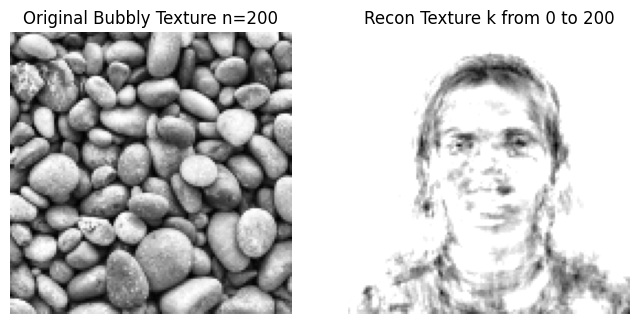

In [88]:
# Use k components to reconstruct non-face image
a = min(0, pca.n_components_)
b = min(200, pca.n_components_)
tex_img_idx = 3
X_target = X_obj

# get PCA coefficients for the texture image
coeffs_tex = pca.transform(X_target[tex_img_idx:tex_img_idx+1])  # shape (1, n_components)
# manual reconstruction using only first k components
recon_tex = mean_face + np.dot(coeffs_tex[:, a:b], components[a:b, :])  # shape (1, n_pixels)
recon_tex = recon_tex.ravel()
# restore to image shape
if grayscale:
    recon_tex_img = recon_tex.reshape(target_size[::-1])
    orig_tex_img = X_target[tex_img_idx].reshape(target_size[::-1])
else:
    recon_tex_img = recon_tex.reshape((target_size[1], target_size[0], 3))
    orig_tex_img = X_target[tex_img_idx].reshape((target_size[1], target_size[0], 3))
recon_tex_img = np.clip(recon_tex_img, 0, 255).astype(np.uint8)
orig_tex_img  = np.clip(orig_tex_img,  0, 255).astype(np.uint8)

# display
texture_image_name = os.path.basename(texture_paths[tex_img_idx])
texture_person_id = str.capitalize(texture_image_name.split('_')[0])
plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.title(f'Original {texture_person_id} Texture n={n_components}'); plt.imshow(orig_tex_img, cmap='gray' if grayscale else None); plt.axis('off')
plt.subplot(1,2,2); plt.title(f'Recon Texture k from {a} to {b}'); plt.imshow(recon_tex_img, cmap='gray' if grayscale else None); plt.axis('off')
plt.show()

# add the reconstructed texture image back to original texture image
# blended = cv2.addWeighted(orig_tex_img, 0.8, recon_tex_img, 0.5, 0)
# # display blended image
# plt.figure(figsize=(4,4))
# plt.title(f'Blended Texture {texture_person_id}'); plt.imshow(blended, cmap='gray' if grayscale else None); plt.axis('off')
# plt.show()

# CAE Training

In [9]:
# -------- USER SETTINGS --------
OUT_DIR = "outputs"
BATCH_SIZE = 16          # reduce from 16
LR = 1e-3
EPOCHS = 60              # reduce from 60
LATENT_DIM = 128        # bottleneck dimension
IMG_SIZE = 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0
# -------------------------------

os.makedirs(OUT_DIR, exist_ok=True)

# ---- Dataset ----
class FaceDataset(Dataset):
    def __init__(self, files, transforms=None):
        self.files = files
        self.transforms = transforms

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        p = self.files[idx]
        img = Image.open(p).convert("L")   # grayscale
        if self.transforms:
            img = self.transforms(img)
        return img

# Transforms: augment heavily if you have few images
train_transforms = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.9,1.0), ratio=(0.9,1.1)),
    T.RandomRotation(10),                  # small rotations
    T.RandomHorizontalFlip(p=0.5),
    T.ToTensor(),                          # converts to [0,1]
])

val_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
])

# collect files

# all_files = sorted(glob(os.path.join(DATA_DIR, "*.jpg")))
# if len(all_files) == 0:
#     raise RuntimeError(f"No images found in {DATA_DIR}")
all_files = []
for d in face_dirs:
    if os.path.isdir(d):
        all_files.extend(sorted(glob(os.path.join(d, '*.jpg'))))

# Split small val set if needed
val_split = max(1, int(0.1 * len(all_files)))
train_files = all_files[val_split:]
val_files = all_files[:val_split]

train_ds = FaceDataset(train_files, transforms=train_transforms)
val_ds = FaceDataset(val_files, transforms=val_transforms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"Found {len(all_files)} images → train {len(train_ds)}, val {len(val_ds)}")
print("Device:", DEVICE)

Found 2800 images → train 2520, val 280
Device: cpu


In [11]:
# ---- small Convolutional Autoencoder ----
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        # Encoder
        self.enc = nn.Sequential(
            nn.Conv2d(1, 32, 4, stride=2, padding=1),  # 128 -> 64
            nn.BatchNorm2d(32),
            nn.ReLU(True),

            nn.Conv2d(32, 64, 4, stride=2, padding=1), # 64 -> 32
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.Conv2d(64, 128, 4, stride=2, padding=1),# 32 -> 16
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.Conv2d(128, 256, 4, stride=2, padding=1),#16 -> 8
            nn.BatchNorm2d(256),
            nn.ReLU(True),
        )

        # Bottleneck: conv feature map -> vector
        # feature map size now: (256, 8, 8) -> flatten to 16384
        self.flatten = nn.Flatten()
        self.fc_enc = nn.Linear(256 * 8 * 8, latent_dim)

        # Decoder
        self.fc_dec = nn.Linear(latent_dim, 256 * 8 * 8)
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), # 8->16
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),  #16->32
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),   #32->64
            nn.BatchNorm2d(32),
            nn.ReLU(True),

            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1),    #64->128
            nn.Sigmoid()   # output in [0,1]
        )

    def encode(self, x):
        x = self.enc(x)
        x = self.flatten(x)
        z = self.fc_enc(x)
        return z

    def decode(self, z):
        x = self.fc_dec(z)
        x = x.view(-1, 256, 8, 8)
        x = self.dec(x)
        return x

    def forward(self, x):
        z = self.encode(x)
        out = self.decode(z)
        return out

In [ ]:
# ---- Train setup ----
model = ConvAutoencoder(latent_dim=LATENT_DIM).to(DEVICE)
print(model)

# ---- Optimizer & Loss ----
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, factor=0.5)
criterion = nn.MSELoss() # mean squared error

# ---- Training loop ----
best_val = 1e9
for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for batch in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        recon = model(batch)
        loss = criterion(recon, batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch.size(0)
    train_loss /= len(train_loader.dataset)

    # validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(DEVICE)
            recon = model(batch)
            loss = criterion(recon, batch)
            val_loss += loss.item() * batch.size(0)
    val_loss /= len(val_loader.dataset)

    scheduler.step(val_loss)

    print(f"Epoch {epoch:03d} Train Loss: {train_loss:.6f}  Val Loss: {val_loss:.6f}")

    # save best model and example reconstructions
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), os.path.join(OUT_DIR, "cae_best.pth"))
        # save a grid of reconstructions
        model.eval()
        with torch.no_grad():
            batch = next(iter(val_loader)).to(DEVICE)
            recon = model(batch)
            # show originals and reconstructions side-by-side
            n = min(8, batch.size(0))
            orig = batch[:n]
            rec = recon[:n]
            grid = torch.cat([orig, rec], dim=0)  # first row originals, second row recon
            save_image(grid, os.path.join(OUT_DIR, f"recon_epoch_{epoch:03d}.png"), nrow=n, normalize=False)
        print("Saved best model and reconstructions.")

# final save
torch.save(model.state_dict(), os.path.join(OUT_DIR, "cae_final.pth"))
print("Training finished. Models and reconstructions are saved to", OUT_DIR)


ConvAutoencoder(
  (enc): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc_enc): Linear(in_features=16384, out_features=128, bias=True)
  (fc_dec): Linear(in_features=128, out_features=16384, bias=True)
  (d

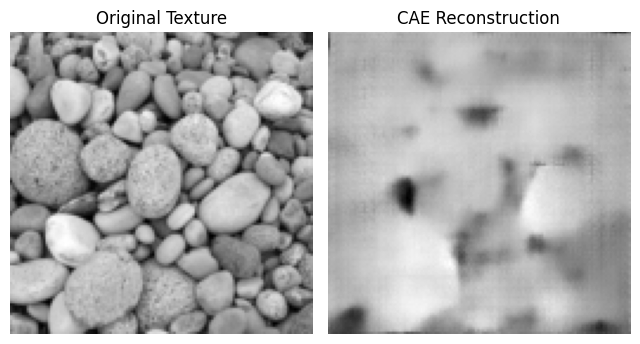

Processed texture image: stained_0086.jpg


In [189]:
# ---- Load trained model and test on non-face image ----
tex_img_idx = 6
# MODEL = "cae_best.pth"
MODEL = "cae_all_direction_best.pth"
target_paths = object_paths

# Load the trained model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ConvAutoencoder(latent_dim=LATENT_DIM).to(device)
model.load_state_dict(torch.load(os.path.join(OUT_DIR, MODEL), map_location=device))
model.eval()

# Load and preprocess texture image
img_path = target_paths[tex_img_idx]  # Choose your texture image index
target_img = Image.open(img_path).convert("L")

# Transform to tensor
transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
])
target_tensor = transform(target_img).unsqueeze(0).to(device)  # Add batch dimension

# Generate reconstruction through CAE
with torch.no_grad():
    target_recon = model(target_tensor)
# Convert back to numpy for visualization
target_orig = target_tensor.squeeze().cpu().numpy()
target_recon_np = target_recon.squeeze().cpu().numpy()

# Display results
fig, axes = plt.subplots(1, 2, figsize=(6.5, 4))
axes[0].imshow(target_orig, cmap='gray')
axes[0].set_title('Original Texture')
axes[0].axis('off')

axes[1].imshow(target_recon_np, cmap='gray')
axes[1].set_title('CAE Reconstruction')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"Processed texture image: {os.path.basename(texture_img_path)}")

# Pretrained VAE

In [54]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [55]:
# ---- VAE Model Definition ----
class VAE(nn.Module):
    def __init__(self, latent_dim=200):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim

        # ENCODER
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),   # 64 → 32
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1),  # 32 → 16
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1), # 16 → 8
            nn.ReLU(),
            nn.Conv2d(128, 256, 4, 2, 1),# 8 → 4
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent_dim)

        # DECODER
        self.decoder_input = nn.Linear(latent_dim, 256 * 4 * 4)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), # 4 → 8
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  # 8 → 16
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),   # 16 → 32
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1),    # 32 → 64
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        h = h.flatten(start_dim=1)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.decoder_input(z)
        h = h.view(-1, 256, 4, 4)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar


In [57]:
# 1) Load model
model = VAE(latent_dim=200)
state = torch.load("vae_celeba_latent_200_epochs_10_batch_64_subset_80000.pth", map_location="cpu")
model.load_state_dict(state)
model.eval()


VAE(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): ReLU()
  )
  (fc_mu): Linear(in_features=4096, out_features=200, bias=True)
  (fc_logvar): Linear(in_features=4096, out_features=200, bias=True)
  (decoder_input): Linear(in_features=200, out_features=4096, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2)

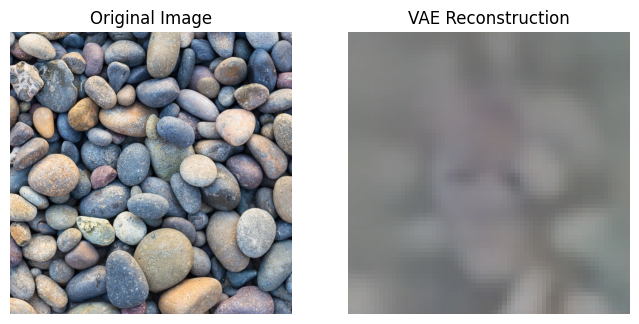

In [63]:
# 2) Preprocess a non-face image to match model's training format
from PIL import Image
from torchvision import transforms

# image_dir = "archive/originalimages_part1" + "/1-13.jpg"
image_dir = "object/" + "rock1.jpg"

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

# 3) Encode and decode image
img = Image.open(image_dir).convert("RGB")
# center crop to square if needed
width, height = img.size
min_side = min(width, height)
left = (width - min_side) / 2
top = (height - min_side) / 2
right = (width + min_side) / 2
bottom = (height + min_side) / 2
img = img.crop((left, top, right, bottom))

x = transform(img).unsqueeze(0)
with torch.no_grad():
    mu, logvar = model.encode(x)
    # z = mu
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    z = mu + eps * std
    recon = model.decode(z)

recon = recon.squeeze().permute(1,2,0).clamp(0,1).numpy()

# def contrast_stretch(img):
#     p2, p98 = np.percentile(img, (3, 97))
#     img = np.clip((img - p2) / (p98 - p2), 0, 1)
#     return img
# recon = contrast_stretch(recon)

# 4) display image
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(img)
axes[0].axis('off')
axes[0].set_title("Original Image")

plt.imshow(recon)
axes[1].axis('off')
axes[1].set_title("VAE Reconstruction")

plt.show()

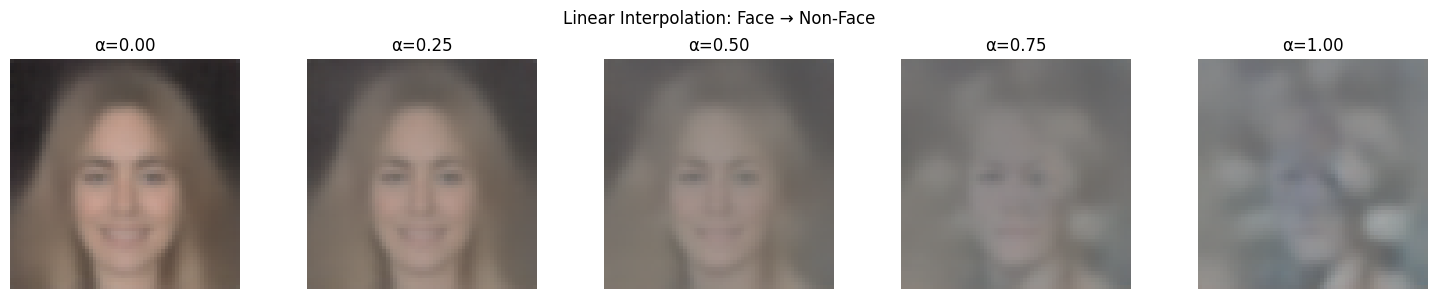

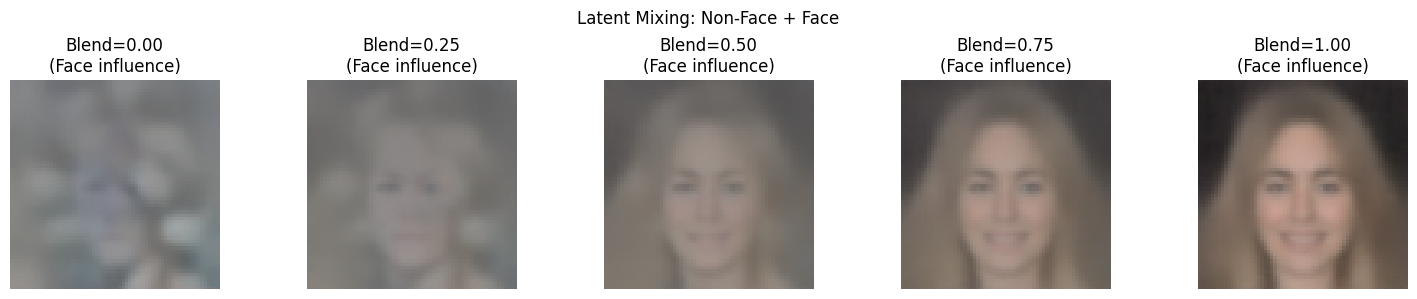

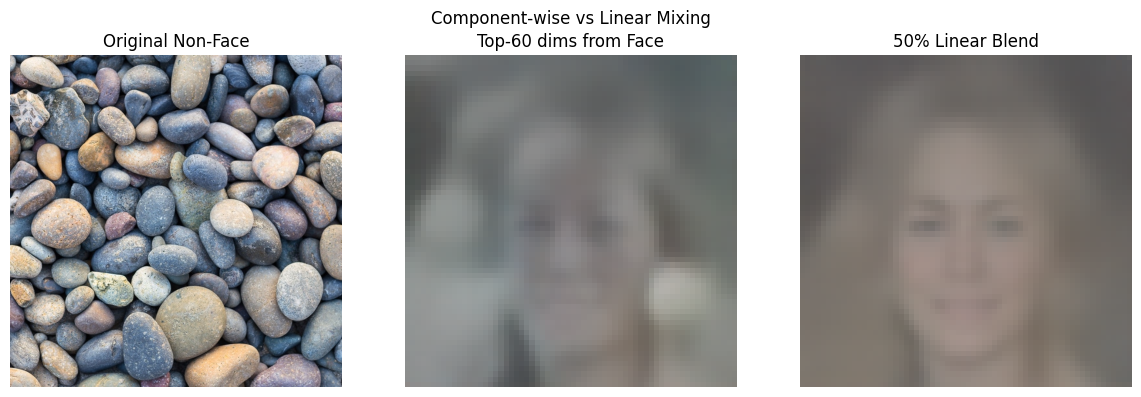

In [86]:
# Latent space manipulations
# Load a face image to extract face latents
face_image_path = "object/face2.jpg"
non_face_image_path = "object/rock1.jpg"

# Preprocessing function for both types
def encode_image_vae(img_path, transform, model, device):
    """Encode an image to latent space."""
    img = Image.open(img_path).convert("RGB")
    # Center crop to square
    width, height = img.size
    min_side = min(width, height)
    left = (width - min_side) / 2
    top = (height - min_side) / 2
    right = (width + min_side) / 2
    bottom = (height + min_side) / 2
    img = img.crop((left, top, right, bottom))
    
    x = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        mu, logvar = model.encode(x)
    return mu, logvar, img

def decode_latent_vae(z, model, device):
    """Decode a latent vector to image."""
    with torch.no_grad():
        recon = model.decode(z)
    return recon.squeeze().permute(1, 2, 0).clamp(0, 1).cpu().numpy()

# 1) Simple linear interpolation between face and non-face
# Encode face and non-face
mu_face, logvar_face, img_face = encode_image_vae(face_image_path, transform, model, device)
mu_nonface, logvar_nonface, img_nonface = encode_image_vae(non_face_image_path, transform, model, device)

# Interpolate in latent space
n_steps = 5
alphas = torch.linspace(0, 1, n_steps).to(device)
interpolations = []

for alpha in alphas:
    z_interp = (1 - alpha) * mu_face + alpha * mu_nonface
    recon_interp = decode_latent_vae(z_interp, model, device)
    interpolations.append(recon_interp)

# Visualize interpolation
fig, axes = plt.subplots(1, n_steps, figsize=(15, 3))
for i, (alpha, recon) in enumerate(zip(alphas, interpolations)):
    axes[i].imshow(recon)
    axes[i].set_title(f"α={alpha.item():.2f}")
    axes[i].axis('off')
plt.suptitle("Linear Interpolation: Face → Non-Face")
plt.tight_layout()
plt.show()

# 2) latent mixing with varying blend ratios
# Define mixing strength
blend_ratios = [0.0, 0.25, 0.5, 0.75, 1.0]  # 0=pure non-face, 1=pure face
mixed_results = []

for blend in blend_ratios:
    # Mix: (1-blend)*non_face + blend*face
    z_mixed = (1 - blend) * mu_nonface + blend * mu_face
    recon_mixed = decode_latent_vae(z_mixed, model, device)
    mixed_results.append(recon_mixed)

# Visualize mixing
fig, axes = plt.subplots(1, len(blend_ratios), figsize=(15, 3))
for i, (blend, recon) in enumerate(zip(blend_ratios, mixed_results)):
    axes[i].imshow(recon)
    axes[i].set_title(f"Blend={blend:.2f}\n(Face influence)")
    axes[i].axis('off')
plt.suptitle("Latent Mixing: Non-Face + Face")
plt.tight_layout()
plt.show()

# 3) Component-wise mixing (partial latent replacement)
# Mix only top-k components (dims with highest face variance)
k_components = 60  # mix only top 50 dimensions

z_partial_mix = mu_nonface.clone()
# Replace top-k dims with face latents
z_partial_mix[:, :k_components] = mu_face[:, :k_components]

recon_partial = decode_latent_vae(z_partial_mix, model, device)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_nonface)
axes[0].set_title("Original Non-Face")
axes[0].axis('off')

axes[1].imshow(recon_partial)
axes[1].set_title(f"Top-{k_components} dims from Face")
axes[1].axis('off')

axes[2].imshow(mixed_results[2])  # 50% blend from above
axes[2].set_title("50% Linear Blend")
axes[2].axis('off')

plt.suptitle("Component-wise vs Linear Mixing")
plt.tight_layout()
plt.show()

# 4) Variance-weighted mixing
# Mix based on face variance in each latent dimension
# std_face = torch.exp(0.5 * logvar_face)
# std_nonface = torch.exp(0.5 * logvar_nonface)

# # Adaptive blending: higher variance dims get more face influence
# face_variance = std_face ** 2
# blend_strength = torch.clamp(face_variance / (face_variance + std_nonface ** 2), 0, 1)

# # Apply weighted blending per dimension
# z_adaptive = mu_nonface.clone()
# z_adaptive = (1 - blend_strength) * mu_nonface + blend_strength * mu_face

# recon_adaptive = decode_latent_vae(z_adaptive, model, device)

# fig, axes = plt.subplots(1, 3, figsize=(12, 4))
# axes[0].imshow(img_nonface)
# axes[0].set_title("Original Non-Face")
# axes[0].axis('off')

# axes[1].imshow(recon_adaptive)
# axes[1].set_title("Variance-Weighted Mix")
# axes[1].axis('off')

# axes[2].imshow(mixed_results[2])
# axes[2].set_title("Uniform 50% Blend")
# axes[2].axis('off')

# plt.suptitle("Adaptive Mixing Comparison")
# plt.tight_layout()
# plt.show()

# High-Frequency Diffusion Editing

In [ ]:
! pip install diffusers transformers accelerate torch torchvision opencv-python

In [89]:
import torch
import numpy as np
import cv2
from PIL import Image
import torchvision.transforms as T
from diffusers import StableDiffusionImg2ImgPipeline
from matplotlib import pyplot as plt

In [90]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cpu


(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

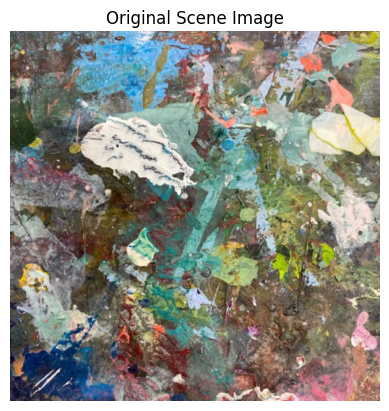

In [109]:
img = Image.open("object/messy.jpg").convert("RGB")

# center crop to square if needed
width, height = img.size
min_side = min(width, height)
left = (width - min_side) / 2
top = (height - min_side) / 2
right = (width + min_side) / 2
bottom = (height + min_side) / 2
img = img.crop((left, top, right, bottom))

transform = T.Compose([
    T.Resize((512, 512)),
    T.ToTensor()
])

x_ref = transform(img).unsqueeze(0).to(device)

plt.imshow(np.transpose(x_ref.squeeze().cpu().numpy(), (1,2,0)))
plt.title("Original Scene Image")
plt.axis("off")


Text(0.5, 1.0, 'High Frequency')

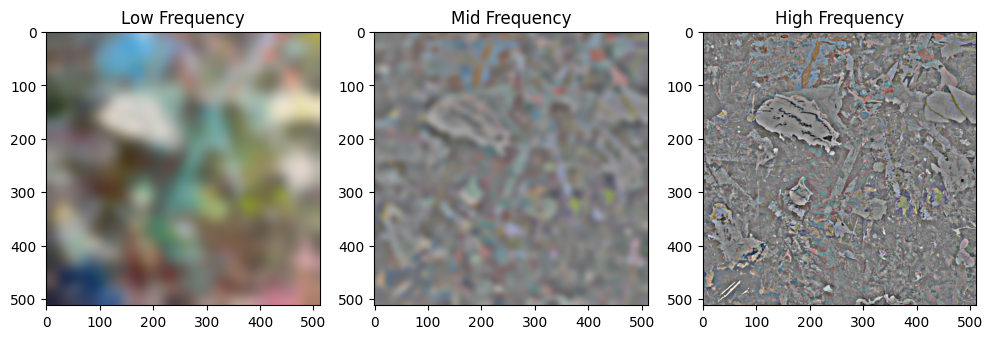

In [110]:
def gaussian_blur_tensor(x, kernel_size=51, sigma=8):
    x_np = x.squeeze(0).permute(1,2,0).cpu().numpy()
    x_blur = cv2.GaussianBlur(x_np, (kernel_size, kernel_size), sigma)
    return torch.tensor(x_blur).permute(2,0,1).unsqueeze(0).to(x.device)

# Low frequency (structure)
low = gaussian_blur_tensor(x_ref, kernel_size=71, sigma=12)

# Mid frequency
mid_raw = x_ref - low
mid = gaussian_blur_tensor(mid_raw, kernel_size=31, sigma=6)

# High frequency
high = x_ref - low - mid


plt.figure(figsize=(12,8))

plt.subplot(1,3,1)
plt.imshow(np.transpose(low.squeeze().cpu().numpy(), (1,2,0)))
plt.title("Low Frequency")

plt.subplot(1,3,2)
plt.imshow(np.clip(np.transpose(mid.squeeze().cpu().numpy(), (1,2,0)) + 0.5, 0, 1))
plt.title("Mid Frequency")

plt.subplot(1,3,3)
plt.imshow(np.clip(np.transpose(high.squeeze().cpu().numpy(), (1,2,0)) + 0.5, 0, 1))
plt.title("High Frequency")

Keyword arguments {'dtype': torch.float32} are not expected by StableDiffusionImg2ImgPipeline and will be ignored.
Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 32.68it/s]


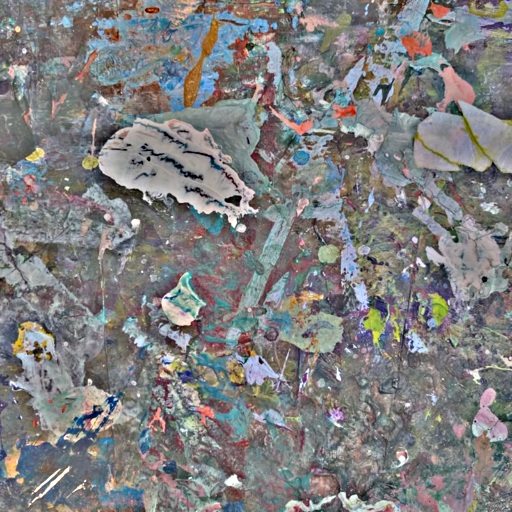

In [111]:
# Load Stable Diffusion Img2Img Pipeline
pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    dtype=torch.float16 if device=="cuda" else torch.float32,
    safety_checker=None,
    requires_safety_checker=False
).to(device)

# Convert high-frequency tensor to PIL image
# high_img = high.squeeze().permute(1,2,0).detach().cpu().numpy()
# high_img = (high_img - high_img.min()) / (high_img.max() - high_img.min())
# high_img = (high_img * 255).astype(np.uint8)
# high_img = Image.fromarray(high_img)
# high_img

# Generate edited high-frequency details
edit_band = mid + high

edit_norm = edit_band.clone()
edit_norm -= edit_norm.mean()
edit_norm /= (edit_norm.std() + 1e-6)
edit_norm = torch.clamp(edit_norm * 0.15 + 0.5, 0, 1)

edit_img = edit_norm.squeeze().permute(1,2,0).cpu().numpy()
edit_img = (edit_img * 255).astype(np.uint8)
edit_img = Image.fromarray(edit_img)
edit_img


100%|██████████| 24/24 [00:57<00:00,  2.39s/it]


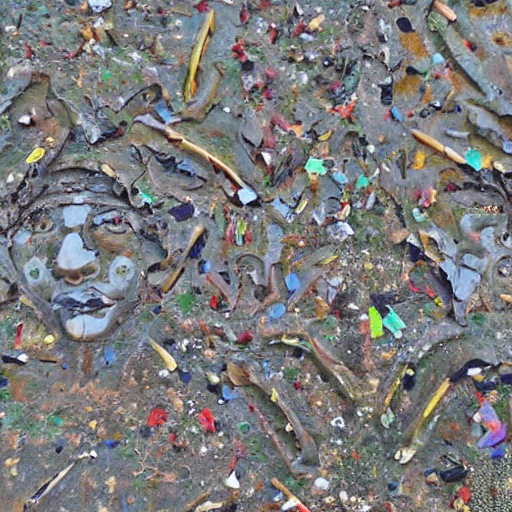

In [144]:
# diffusion editing on high-frequency details
# prompt = "subtle pareidolia face emerging from natural textures, artistic"
# negative_prompt = "clear portrait, eyes, nose, mouth, skin, lips,"


prompt = """
face features formed by objects, organic facial symmetry,
"""
prompts = """
hidden face structure formed by natural objects
subtle pareidolia, organic facial symmetry,
embedded in environment textures, illusion, ambiguous,
vague bilateral facial symmetry
"""

negative_prompt = """
photoreal portrait, repeating patterns, floating circles 
"""
# floating eyes, studio lighting,
# skin pores, clean facial features, sharp portrait

result = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=edit_img,
    strength=0.4,            # allow some structure
    guidance_scale=5,      # lower => more natural pareidolia
    num_inference_steps=60
)

edited_img = result.images[0]
edited_img

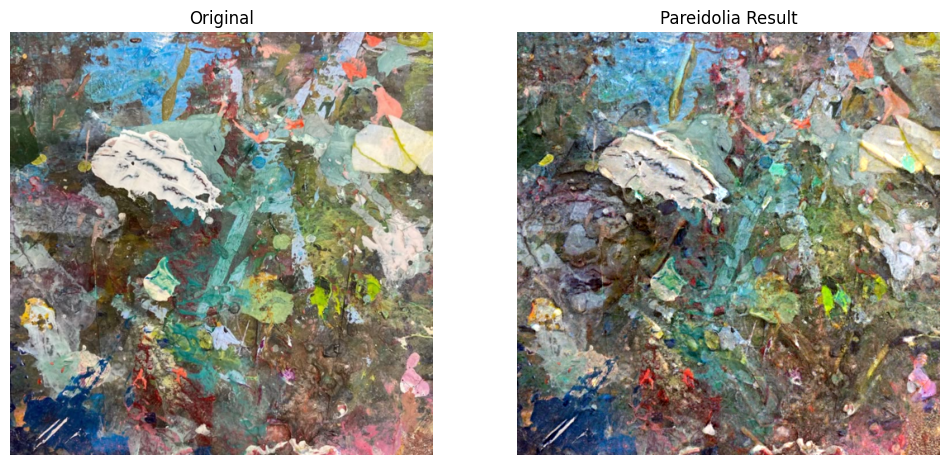

In [145]:
# Convert modified high-frequency PIL image back to tensor
edited_tensor = transform(edited_img).unsqueeze(0).to(device)

# Convert normalized edit back to frequency space
edited_band = (edited_tensor - 0.5) / 0.15
edited_band *= (edit_band.std() + 1e-6)
edited_band += edit_band.mean()

# Recombine low and modified high frequency components
# final = low + edited_band + high
alpha_mid = 0.7   # mid frequency strength
alpha_high = 0.8  # high frequency strength

final = low + alpha_mid * edited_band + alpha_high * high
final = torch.clamp(final, 0, 1)

# Visualize final result compared to original
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(np.transpose(x_ref.squeeze().cpu().numpy(), (1,2,0)))
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(np.transpose(final.squeeze().cpu().numpy(), (1,2,0)))
plt.title("Pareidolia Result")
plt.axis("off")
plt.show()

In [64]:
# Save final image
final_img = final.squeeze().permute(1,2,0).cpu().numpy()
final_img = (final_img * 255).astype(np.uint8)
final_img = Image.fromarray(final_img)
final_img.save("outputs/pareidolia_forest2.png")